# Local metric field (paper Fig. 5)

* **Goal**: plot Fig. 5, the local metric field projected onto the leading eigenvectors of G(x). Starting from a reference image, we perturb it along the two leading eigenvectors of the multi-scale Fisher metric G(x) of the Inception model. At every perturbed image, the metrics of the Inception and ResNet-50 models are projected onto that same 2-D subspace and drawn as ellipses (A: G(x), B: the Fisher metric J(x); V1 left, V4 right).
* **Reading it**: ellipses that vary smoothly and agree between the two models mean that the geometry reflects the neural code and not the fitted model; ellipses that jump around and disagree mean it reflects the model. In the paper, G(x) is stable and J(x) is not.
* **Cost**: every grid point of every model needs one G(x) estimate (about 15 s on an RTX 5090). The default 5 x 5 grid with both areas and both models takes about 26 minutes on one GPU, so no cluster is needed; J(x) takes seconds. Processes sharing one GPU are slower than one, so a single background process is used.
* All supporting functions are in `src/local_metric_field.py`; the computation is `stages/06_metric_field.py` and the drawing `figures/fig5.py`. This notebook only sets parameters and calls them.

## 1. Choose what to compute

The parameters are set in the next cell. Typical settings:

| Case | `GRID_SIZE` | `AREAS` | `METRICS` | Time on one RTX 5090 |
|---|---|---|---|---|
| quick check | 3 | `("V1",)` | `("J",)` | seconds |
| G(x) and J(x) for one area | 3 | `("V1",)` | `("G", "J")` | about 5 min |
| the full figure (default) | 5 | `("V1", "V4")` | `("G", "J")` | about 24 min (measured) |

* `IMG_IDX` is the reference image, an index into the TinyImageNet validation images (the same order as the G(x) estimation of notebook 2).
* The grid is `GRID_SIZE` x `GRID_SIZE` images around the reference, `x(a, b) = x0 + a * e1 * v1 + b * e2 * v2`, where `v1`, `v2` are the leading eigenvectors of the metric being drawn at the reference image (Inception).
* **Step sizes** (`STEPS`, per metric). G uses `0.5 sqrt(lambda)`, about 0.3. J(x) has far larger eigenvalues, so the same rule would give steps of 5 to 7: the perturbed images are clipped to [-1, 1], the local structure is lost, and off-centre the ResNet-50 ellipses come out larger than the Inception ones. A small fixed step of 0.3, the size of G's steps, keeps the field smooth and the Inception ellipses outside the ResNet-50 ones, as in the paper's panel B. The paper does not state its step sizes, so this is a choice; the stage-6 script itself uses `0.5 sqrt(lambda)` for both metrics, and this notebook runs it once per metric.
* **Reference image 64.** The paper does not state its reference image, and the field depends strongly on it. In the paper's panel B the central ellipses are horizontal and, towards the edges, the ellipses turn so that they point radially away from the centre, with Inception outside ResNet-50. `tools/scan_metric_field_images.py` scanned the 200 test images with six perturbation settings (result in `analysis/results/metric_field_scan.jsonl`): image 64 with a fixed step of 0.2 to 0.3 is the only one that is both radial (score 0.81 in V1 and 0.91 to 0.94 in V4, where 1 is perfectly radial and random orientations give 0.64) and has Inception clearly outside ResNet-50 (area ratio 5 to 6 in V1, 2.5 to 3 in V4). Image 0, the default of the stage-6 script, shows the radial pattern only for ResNet-50.
* Ellipse convention: width `2 sqrt(mu_max)` and height `2 sqrt(mu_min)` of the projected 2 x 2 matrix, angle of the major axis from the `v1` axis. Within each plot all ellipses share one scale, so sizes compare across grid points and models, not between plots.
* **Not reproduced:** in the paper's panel A the V1 ellipses of G(x) are strongly elongated. Here G(x) is nearly isotropic in the plane (the ratio of its two leading eigenvalues is 1.3 to 1.65 for every image tried), so the ellipses are nearly round. Possible causes are the diffusion checkpoints (epoch 120 here, 200 in the paper's configuration) or a different definition used for the paper.

In [13]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root
root = Path.cwd().resolve()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

# import custom packages
from src import local_metric_field as lmf
from src import subspace_alignment as sa
importlib.reload(lmf)     # update the modules without restarting the kernel

# parameters (see the table above)
IMG_IDX = 64                         # reference image (index into the TinyImageNet validation images); 64: best match of the paper's panel B
GRID_SIZE = 5                        # odd: the grid is GRID_SIZE x GRID_SIZE images
STEPS = {                            # perturbation size per metric: (rule, size)
    "G": ("sqrt_lambda", 0.5),       #   "sqrt_lambda": step_i = size * sqrt(lambda_i)   (about 0.3 for G)
    "J": ("fixed", 0.3),             #   "fixed": step_i = size                          (J's eigenvalues are far larger)
}
AREAS = ("V1", "V4")                 # ("V1",) for a quicker run
METRICS = ("G", "J")                 # G(x) is the expensive one
DEVICE = "gpu"                       # "gpu" | "cpu" (a CPU is far slower)

job = lmf.MetricFieldJob(img_idx=IMG_IDX, grid_size=GRID_SIZE, steps=STEPS,
                         areas=AREAS, metrics=METRICS, device=DEVICE)

RUN = True                           # False: only print the estimate. True: launch the computation.
RESTART = True                      # True: first delete this job's results, to recompute them from scratch

print(job)
lmf.print_estimate(job)

MetricFieldJob(img_idx=64, grid_size=5, steps={'G': ('sqrt_lambda', 0.5), 'J': ('fixed', 0.3)}, reference_encoder='inception', other_encoder='resnet50', areas=('V1', 'V4'), metrics=('G', 'J'), device='gpu')
102 G(x) estimates and 102 J(x) evaluations: about 26.0 min on one GPU (a G(x) estimate takes ~15 s on an RTX 5090).
CPU times: user 497 μs, sys: 987 μs, total: 1.48 ms
Wall time: 1.8 ms


MetricFieldEstimate(g_estimates=102, j_evaluations=102, seconds=1560.6)

## 2. Run

The computation runs in a background process: it keeps going if the notebook kernel dies, finished (metric, area) parts are kept, and launching again computes only what is missing. The log is `runs/logs/metric_field.log`. To recompute from scratch set `RESTART = True` above (this deletes only this job's result files).

In [14]:
%%time

if not RUN:
    print("RUN is False: nothing was started. Set RUN = True above to launch.")
else:
    if RESTART:
        lmf.clear_results(job)
    if lmf.is_complete(job):
        proc = None
        print("All parts are already computed: nothing to launch.")
    else:
        proc = lmf.launch(job)
        print(proc)

deleted 4 result file(s)
{'pid': 1086197, 'log': '/home/steeve/steeve/idv/code/MultiscaleInformationGeometry/runs/logs/metric_field.log', 'device': 'gpu'}
CPU times: user 159 μs, sys: 975 μs, total: 1.13 ms
Wall time: 1.28 ms


### Wait for the computation

This cell blocks the notebook while the process runs and shows a progress bar over the (metric, area) parts; the bar moves when a part is finished, so with one area it moves only a few times. **Interrupting the kernel (the stop button) stops the process too**; finished parts are kept. To only stop waiting, pass `stop_on_interrupt=False`. If the kernel dies, the process keeps running; `lmf.stop()` stops it from a later session.

* **Execution time**: 
    * 23 min (1 GPU, grid_size=5, areas=("V1", "V4"))

In [15]:
%%time 

lmf.wait(job, globals().get("proc"))

local metric field:   0%|      | 0/4 [00:00<?, ?part/s, 1 process running; 0/4 (metric, area) parts]

all parts done
CPU times: user 33.9 ms, sys: 8.54 ms, total: 42.5 ms
Wall time: 24min 45s


True

## 3. Plot Fig. 5

A: G(x), B: the Fisher metric J(x); the reference (Inception) is drawn solid blue and the comparison (ResNet-50) dashed orange; parts that were not computed are left blank.

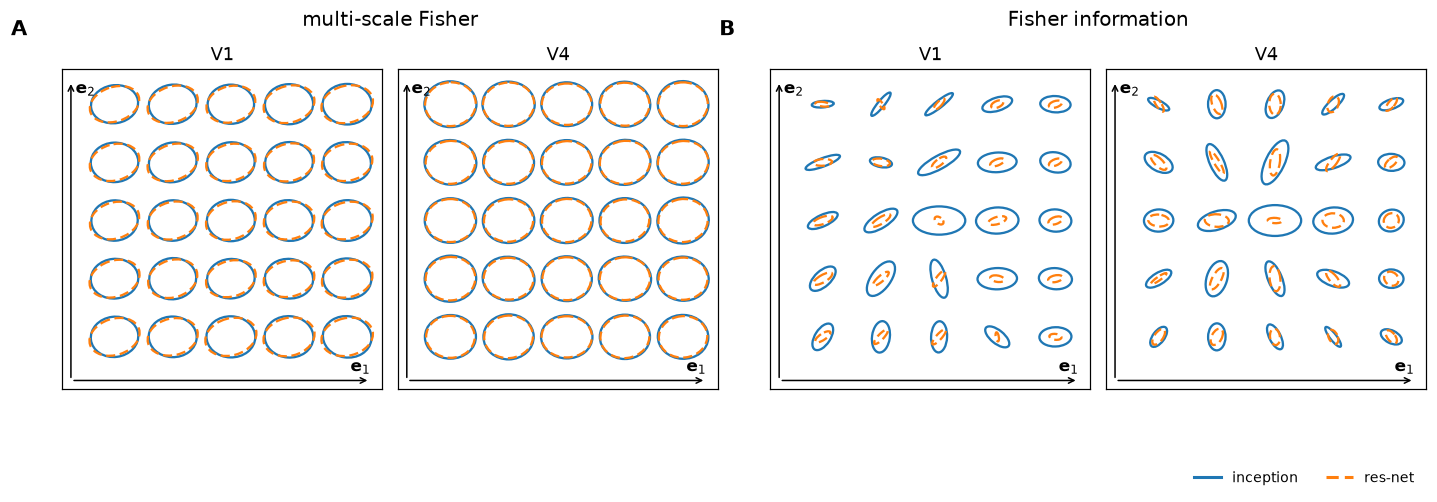

CPU times: user 205 ms, sys: 839 μs, total: 206 ms
Wall time: 205 ms


In [16]:
%%time

if lmf.progress(job)[0] == 0:
    print("Nothing to plot yet: run the cells above first.")
else:
    sa.show_figure(lmf.plot_metric_field(job))